# 06D — SwAV pooled representation analysis

This notebook analyses the completed production run:

`swav_resnet18_pooled_broad_natural_seed42_full_3447013`

## Evaluation policy

- The completed training run is read-only.
- Training and validation embeddings are checked against the frozen manifests.
- Model selection and development analysis use train and validation data only.
- The held-out test split is not loaded or accessed.
- Clustering is performed in the deterministic 50-component PCA representation.
- UMAP is used only as a visualisation.
- Clusters are representation diagnostics, not proof of geological populations.
- Retrieval metrics are interpreted alongside source-image and sample confounding.
- The same comparison contract used for SimCLR and DeepCluster is retained.


In [1]:
from __future__ import annotations

import json
import math
import sys
from itertools import combinations
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
)

IRP_ROOT = Path("/home/ars223/MSc-GEMS/IRP26")
DEV_ROOT = IRP_ROOT / "plagnetplus-dev"

sys.path.insert(
    0,
    str(DEV_ROOT / "src"),
)

from plagnetplus.evaluation import (
    categorical_enrichment_at_k,
    categorical_precision_at_k,
    embedding_qc_summary,
    entropy_effective_rank,
    evaluate_kmeans_run,
    exact_cosine_neighbours,
    fit_deterministic_pca,
    fit_locality_probe,
    l2_normalise_rows,
    load_embedding_bundle,
    load_embedding_manifest,
    load_training_history,
    pairwise_clustering_stability,
    prepare_cosine_features,
    summarise_pca,
    validate_embedding_manifest_alignment,
)

METHOD = "swav"
DISPLAY_NAME = "SwAV"
RUN_NAME = "swav_resnet18_pooled_broad_natural_seed42_full_3447013"

RUN_ROOT = Path(r"/home/ars223/MSc-GEMS/IRP26/runs/hpc/swav/swav_resnet18_pooled_broad_natural_seed42_full_3447013")
ANALYSIS_ROOT = Path(r"/home/ars223/MSc-GEMS/IRP26/runs/analysis/swav/swav_resnet18_pooled_broad_natural_seed42_full_3447013_v1")

BENCHMARK_ROOT = (
    IRP_ROOT
    / "data"
    / "processed"
    / "plagnetplus"
    / "ssl_unified_v1"
    / "benchmarks"
    / "pooled_broad_p80_10_10_v1"
)

TRAIN_MANIFEST_PATH = (
    BENCHMARK_ROOT
    / "manifests"
    / "crystals_train.csv"
)

VALIDATION_MANIFEST_PATH = (
    BENCHMARK_ROOT
    / "manifests"
    / "crystals_validation.csv"
)

CONTRACT_PATH = (
    IRP_ROOT
    / "runs"
    / "analysis"
    / "registry"
    / "evaluation_contract_v1.json"
)

for directory in (
    ANALYSIS_ROOT,
    ANALYSIS_ROOT / "figures",
    ANALYSIS_ROOT / "tables",
    ANALYSIS_ROOT / "metadata",
    ANALYSIS_ROOT / "embeddings",
    ANALYSIS_ROOT / "clustering",
    ANALYSIS_ROOT / "clustering" / "assignments",
    ANALYSIS_ROOT / "retrieval",
    ANALYSIS_ROOT / "probes",
):
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )

def json_load(path: Path) -> dict[str, Any]:
    return json.loads(
        path.read_text(encoding="utf-8")
    )

def json_ready(value: Any) -> Any:
    if isinstance(value, dict):
        return {
            str(key): json_ready(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [
            json_ready(item)
            for item in value
        ]

    if isinstance(value, np.ndarray):
        return value.tolist()

    if isinstance(value, np.generic):
        return value.item()

    if isinstance(value, Path):
        return str(value)

    if isinstance(value, float) and not math.isfinite(value):
        return None

    return value

def write_json(
    path: Path,
    payload: dict[str, Any],
) -> None:
    path.write_text(
        json.dumps(
            json_ready(payload),
            indent=2,
            sort_keys=True,
        )
        + "\n",
        encoding="utf-8",
    )

def save_current_figure(filename: str) -> None:
    plt.tight_layout()
    plt.savefig(
        ANALYSIS_ROOT
        / "figures"
        / filename,
        dpi=180,
        bbox_inches="tight",
    )
    plt.show()
    plt.close()

def resolve_column(
    frame: pd.DataFrame,
    candidates: tuple[str, ...],
) -> str | None:
    lower_map = {
        column.lower(): column
        for column in frame.columns
    }

    for candidate in candidates:
        if candidate.lower() in lower_map:
            return lower_map[candidate.lower()]

    return None

def align_manifest(
    bundle,
    manifest: pd.DataFrame,
) -> pd.DataFrame:
    keys = pd.DataFrame(
        {
            "crystal_id": (
                bundle.crystal_ids.astype(str)
            ),
            "manifest_order": (
                bundle.manifest_orders.astype(
                    np.int64
                )
            ),
        }
    )

    aligned = keys.merge(
        manifest,
        on=[
            "crystal_id",
            "manifest_order",
        ],
        how="left",
        validate="one_to_one",
        sort=False,
        indicator=True,
    )

    if not bool(
        (aligned["_merge"] == "both").all()
    ):
        raise RuntimeError(
            "Embedding-to-manifest alignment failed."
        )

    return aligned.drop(
        columns="_merge"
    )

print(f"Method: {DISPLAY_NAME}")
print(f"Run: {RUN_NAME}")
print(f"Run root: {RUN_ROOT}")
print(f"Analysis root: {ANALYSIS_ROOT}")
print(f"Python: {sys.executable}")


Method: SwAV
Run: swav_resnet18_pooled_broad_natural_seed42_full_3447013
Run root: /home/ars223/MSc-GEMS/IRP26/runs/hpc/swav/swav_resnet18_pooled_broad_natural_seed42_full_3447013
Analysis root: /home/ars223/MSc-GEMS/IRP26/runs/analysis/swav/swav_resnet18_pooled_broad_natural_seed42_full_3447013_v1
Python: /home/ars223/MSc-GEMS/IRP26/plagnetplus-dev/.venv/bin/python


## 1. Provenance, completion and alignment

The production result, resolved configuration, environment, frozen manifests
and embedding identifiers are validated before any analysis is performed.


In [2]:
run_summary = json_load(
    RUN_ROOT / "run_summary.json"
)

resolved_config = json_load(
    RUN_ROOT
    / "metadata"
    / "resolved_config.json"
)

environment = json_load(
    RUN_ROOT
    / "metadata"
    / "environment.json"
)

manifest_fingerprints = json_load(
    RUN_ROOT
    / "metadata"
    / "manifest_fingerprints.json"
)

contract = json_load(CONTRACT_PATH)

assert run_summary["status"] == "PASS"
assert run_summary["completed_epochs"] == 100

history = pd.read_csv(
    RUN_ROOT / "training_history.csv"
)

required_history_columns = {
    "epoch",
    "split",
    "loss",
    "seconds",
}

missing_history_columns = (
    required_history_columns
    - set(history.columns)
)

if missing_history_columns:
    raise RuntimeError(
        "Training history is missing common columns: "
        f"{sorted(missing_history_columns)}"
    )

for numeric_column in (
    "epoch",
    "loss",
    "seconds",
):
    history[numeric_column] = pd.to_numeric(
        history[numeric_column],
        errors="raise",
    )

history["split"] = (
    history["split"]
    .astype(str)
    .str.strip()
    .str.lower()
)

if len(history) != 200:
    raise RuntimeError(
        "Expected 200 history rows; "
        f"received {len(history)}."
    )

for split_name in (
    "train",
    "validation",
):
    split_history = history.loc[
        history["split"] == split_name
    ]

    if len(split_history) != 100:
        raise RuntimeError(
            f"Expected 100 {split_name} rows; "
            f"received {len(split_history)}."
        )

    observed_epochs = set(
        split_history["epoch"]
        .astype(int)
        .tolist()
    )

    expected_epochs = set(
        range(1, 101)
    )

    if observed_epochs != expected_epochs:
        raise RuntimeError(
            f"{split_name} epochs are incomplete."
        )

train_bundle = load_embedding_bundle(
    RUN_ROOT
    / "embeddings"
    / "train_backbone_embeddings.npz",
    expected_feature_dimension=512,
)

validation_bundle = load_embedding_bundle(
    RUN_ROOT
    / "embeddings"
    / "validation_backbone_embeddings.npz",
    expected_feature_dimension=512,
)

train_manifest_raw = load_embedding_manifest(
    TRAIN_MANIFEST_PATH
)

validation_manifest_raw = load_embedding_manifest(
    VALIDATION_MANIFEST_PATH
)

train_alignment = (
    validate_embedding_manifest_alignment(
        train_bundle,
        train_manifest_raw,
    )
)

validation_alignment = (
    validate_embedding_manifest_alignment(
        validation_bundle,
        validation_manifest_raw,
    )
)

train_manifest = align_manifest(
    train_bundle,
    train_manifest_raw,
)

validation_manifest = align_manifest(
    validation_bundle,
    validation_manifest_raw,
)

assert train_bundle.features.shape == (
    101682,
    512,
)

assert validation_bundle.features.shape == (
    14919,
    512,
)

assert np.isfinite(
    train_bundle.features
).all()

assert np.isfinite(
    validation_bundle.features
).all()

assert len(history) == 200

assert not list(
    RUN_ROOT.rglob("*test*embedding*")
)

provenance = {
    "method": METHOD,
    "run_name": RUN_NAME,
    "status": run_summary["status"],
    "completed_epochs": (
        run_summary["completed_epochs"]
    ),
    "train_embedding_shape": list(
        train_bundle.features.shape
    ),
    "validation_embedding_shape": list(
        validation_bundle.features.shape
    ),
    "train_alignment": train_alignment,
    "validation_alignment": (
        validation_alignment
    ),
    "manifest_fingerprints": (
        manifest_fingerprints
    ),
    "test_split_accessed": False,
}

write_json(
    ANALYSIS_ROOT
    / "metadata"
    / "analysis_provenance.json",
    provenance,
)

display(
    pd.DataFrame(
        [
            {
                "method": DISPLAY_NAME,
                "run_status": (
                    run_summary["status"]
                ),
                "epochs": (
                    run_summary[
                        "completed_epochs"
                    ]
                ),
                "train_rows": (
                    train_bundle.features.shape[0]
                ),
                "validation_rows": (
                    validation_bundle.features.shape[0]
                ),
                "embedding_dimension": (
                    validation_bundle.features.shape[1]
                ),
                "test_split_accessed": False,
            }
        ]
    )
)

print(
    "Manifest columns:",
    validation_manifest.columns.tolist(),
)

print("PROVENANCE AND ALIGNMENT: PASS")


,method,run_status,epochs,train_rows,validation_rows,embedding_dimension,test_split_accessed
0,SwAV,PASS,100,101682,14919,512,False


Manifest columns: ['crystal_id', 'manifest_order', 'source_dataset', 'source_dataset_id', 'source_dataset_version', 'source_schema_version', 'source_identifier_field', 'source_identifier', 'source_manifest', 'source_manifest_order', 'source_manifest_row_1_based', 'locality', 'sample_id', 'physical_sample_id', 'physical_sample_id_method', 'acquisition_id', 'scan_id', 'scan_id_method', 'split_group_id', 'benchmark_id', 'benchmark_split', 'image_root_key', 'image_relative_path', 'image_locator', 'image_sha256', 'image_width_px', 'image_height_px', 'image_side_px', 'image_representation_contract', 'margin_fraction', 'minimum_margin_px', 'margin_px', 'padding_x_px', 'padding_y_px', 'resize_applied', 'source_tile_context_available', 'source_exact_mask_available', 'pixel_provenance_note', 'source_image_relative_path', 'source_image_sha256', 'source_tile_id', 'source_tile_index_1', 'source_tile_index_2', 'source_instance_index', 'segmentation_score', 'mask_area_px', 'bbox_width_px', 'bbox_heig

## 2. SwAV training diagnostics

Training and validation behaviour are plotted using the method’s native
optimisation diagnostics rather than forcing all SSL methods into identical
training plots.


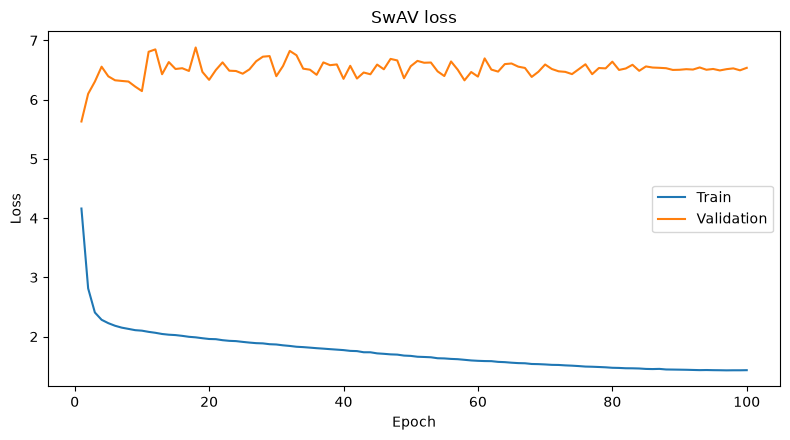

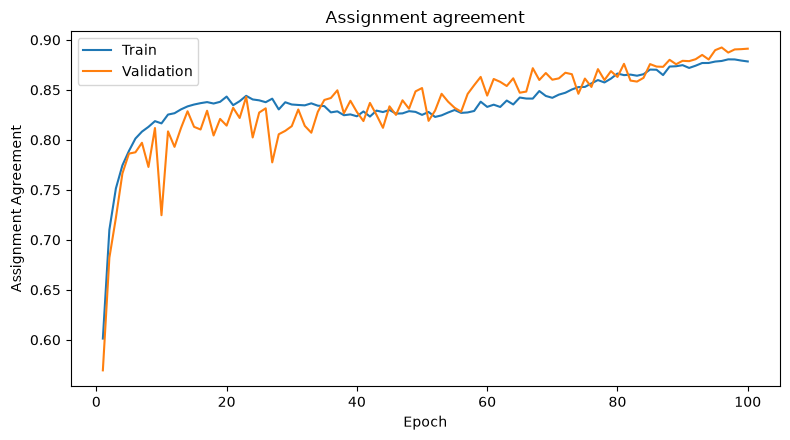

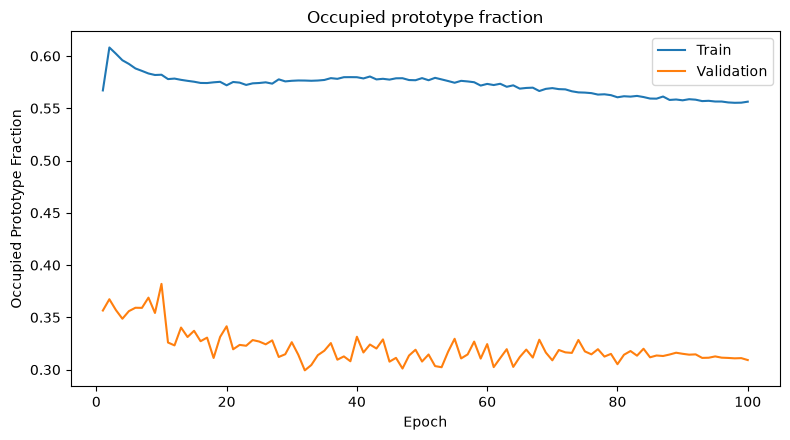

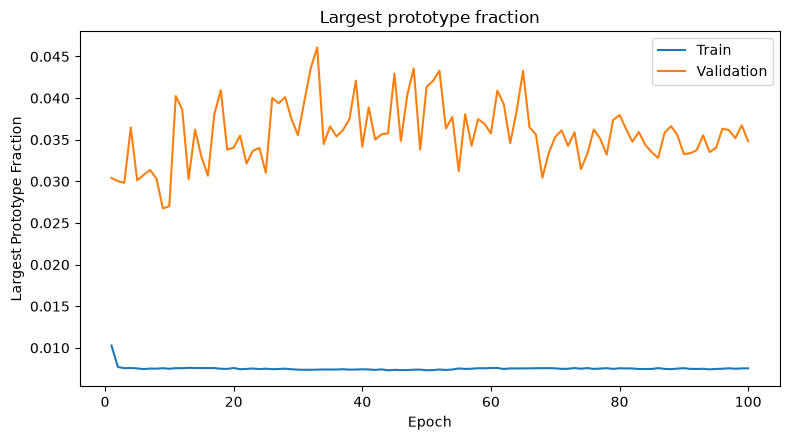

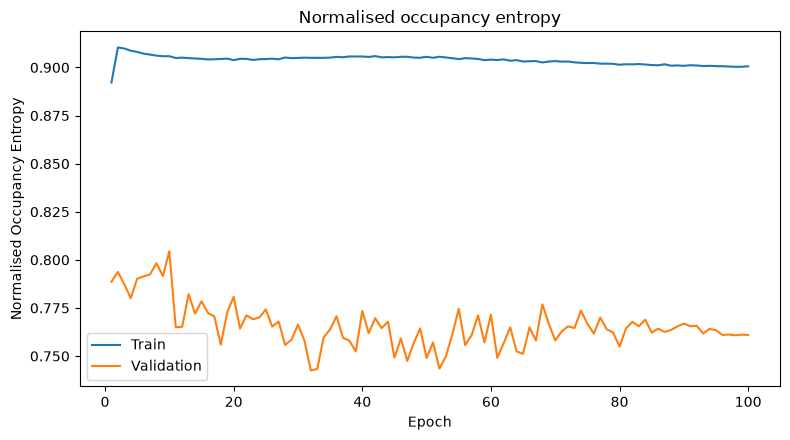

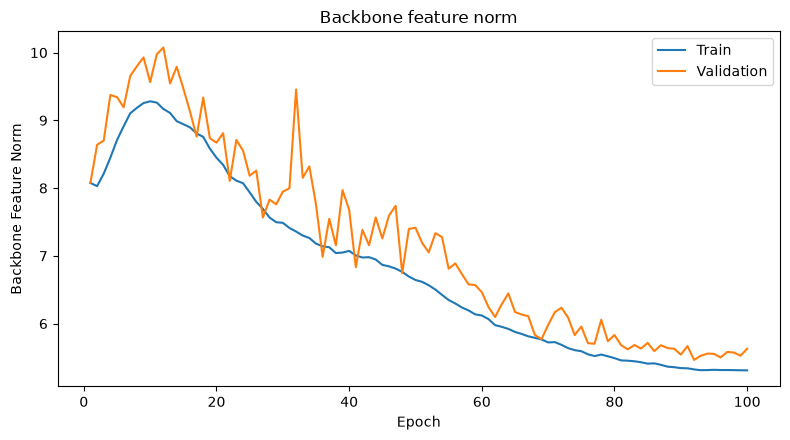

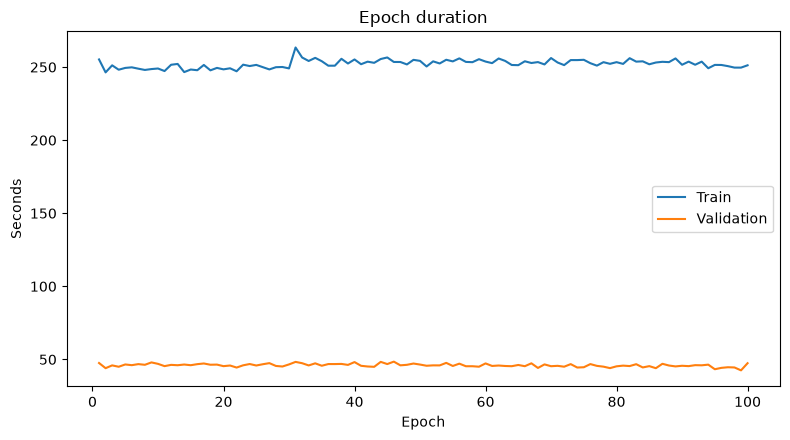

,epoch,split,loss,assignment_entropy,normalised_occupancy_entropy,occupied_prototype_fraction,largest_prototype_fraction,assignment_agreement,backbone_feature_norm,projection_norm,prototype_weight_norm,learning_rate,prototype_gradients_frozen,batches,images,seconds
99,100,train,1.432883,1.246594,0.900633,0.556307,0.007537,0.878434,5.309990,1.0,1.0,0.0,False,397,101632,251.229532
99,100,validation,6.537269,3.935480,0.760962,0.309183,0.034821,0.891213,5.629879,1.0,1.0,0.0,False,59,14919,47.422296


In [3]:
history_train = (
    history.loc[
        history["split"] == "train"
    ]
    .sort_values("epoch")
    .reset_index(drop=True)
)

history_validation = (
    history.loc[
        history["split"] == "validation"
    ]
    .sort_values("epoch")
    .reset_index(drop=True)
)

if METHOD == "simsiam":
    metric_specs = [
        (
            "loss",
            "SimSiam loss",
            "training_loss.png",
        ),
        (
            "mean_cosine_similarity",
            "Mean cosine similarity",
            "cosine_similarity.png",
        ),
        (
            "collapse_level",
            "Collapse diagnostic",
            "collapse_level.png",
        ),
        (
            "projection_standard_deviation",
            "Projection standard deviation",
            "projection_standard_deviation.png",
        ),
        (
            "backbone_feature_norm",
            "Backbone feature norm",
            "backbone_feature_norm.png",
        ),
        (
            "prediction_norm",
            "Prediction norm",
            "prediction_norm.png",
        ),
    ]
else:
    metric_specs = [
        (
            "loss",
            "SwAV loss",
            "training_loss.png",
        ),
        (
            "assignment_agreement",
            "Assignment agreement",
            "assignment_agreement.png",
        ),
        (
            "occupied_prototype_fraction",
            "Occupied prototype fraction",
            "prototype_occupancy.png",
        ),
        (
            "largest_prototype_fraction",
            "Largest prototype fraction",
            "largest_prototype_fraction.png",
        ),
        (
            "normalised_occupancy_entropy",
            "Normalised occupancy entropy",
            "occupancy_entropy.png",
        ),
        (
            "backbone_feature_norm",
            "Backbone feature norm",
            "backbone_feature_norm.png",
        ),
    ]

for metric, title, filename in metric_specs:
    if metric not in history.columns:
        continue

    plt.figure(figsize=(8, 4.5))

    plt.plot(
        history_train["epoch"],
        history_train[metric],
        label="Train",
    )

    plt.plot(
        history_validation["epoch"],
        history_validation[metric],
        label="Validation",
    )

    plt.xlabel("Epoch")
    plt.ylabel(metric.replace("_", " ").title())
    plt.title(title)
    plt.legend()

    save_current_figure(filename)

plt.figure(figsize=(8, 4.5))

plt.plot(
    history_train["epoch"],
    history_train["seconds"],
    label="Train",
)

plt.plot(
    history_validation["epoch"],
    history_validation["seconds"],
    label="Validation",
)

plt.xlabel("Epoch")
plt.ylabel("Seconds")
plt.title("Epoch duration")
plt.legend()

save_current_figure("epoch_duration.png")

training_final = {
    "final_train": (
        history_train.iloc[-1].to_dict()
    ),
    "final_validation": (
        history_validation.iloc[-1].to_dict()
    ),
}

write_json(
    ANALYSIS_ROOT
    / "metadata"
    / "training_final_metrics.json",
    training_final,
)

display(
    pd.DataFrame(
        [
            history_train.iloc[-1],
            history_validation.iloc[-1],
        ]
    )
)


## 3. Embedding quality control and dimensionality

The validation representation is assessed for finite values, inactive
dimensions, pairwise similarity, effective rank and PCA dimensionality.


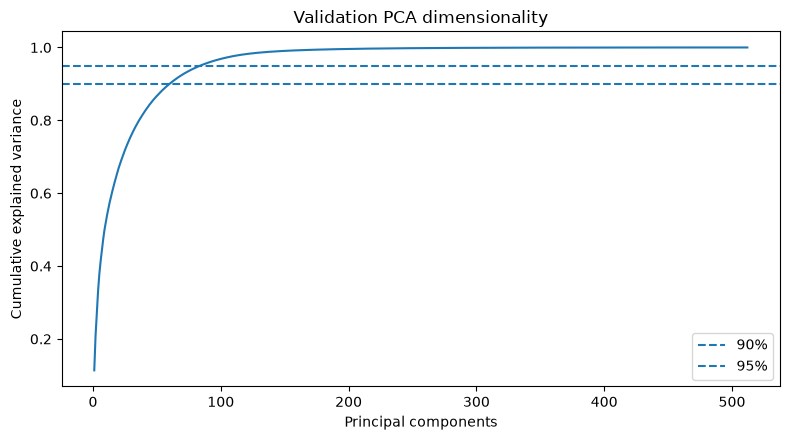

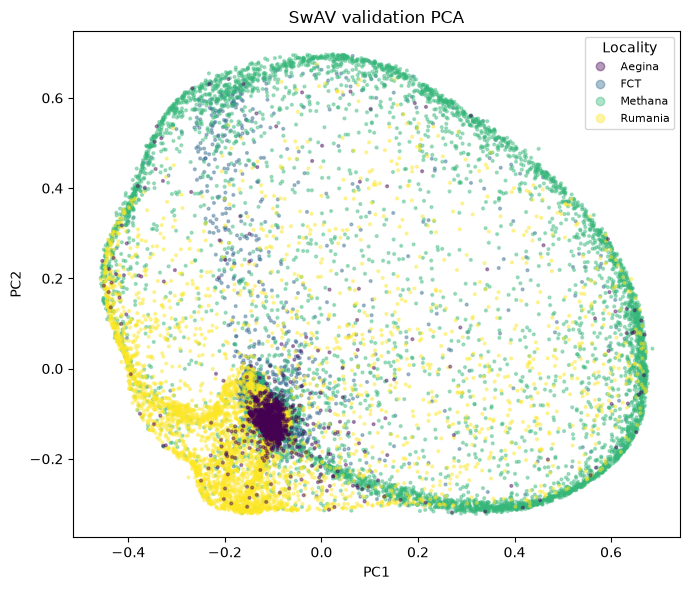

,row_count,feature_dimension,feature_dtype,all_finite,zero_variance_dimensions,near_zero_variance_dimensions,near_zero_variance_threshold,minimum_dimension_standard_deviation,median_dimension_standard_deviation,maximum_dimension_standard_deviation,...,retained_components,variance_retained_by_selected_components,pc1_explained_variance_ratio,pc2_explained_variance_ratio,pc3_explained_variance_ratio,components_for_50_percent_variance,components_for_80_percent_variance,components_for_90_percent_variance,components_for_95_percent_variance,components_for_99_percent_variance
0,14919,512,float32,True,0,0,1.000000e-12,0.000259,0.13504,0.991049,...,50,0.867146,0.113764,0.094211,0.063742,10,37,60,84,147


In [4]:
qc_summary, dimension_table = (
    embedding_qc_summary(
        validation_bundle,
        pair_count=100000,
        pair_seed=42,
    )
)

effective_rank, participation_ratio = (
    entropy_effective_rank(
        validation_bundle.features
    )
)

normalised_validation = l2_normalise_rows(
    validation_bundle.features
)

pca_result = fit_deterministic_pca(
    normalised_validation,
    retained_components=50,
)

pca_summary = summarise_pca(
    pca_result
)

qc_summary.update(
    {
        "entropy_effective_rank": (
            effective_rank
        ),
        "participation_ratio": (
            participation_ratio
        ),
    }
)

write_json(
    ANALYSIS_ROOT
    / "metadata"
    / "embedding_qc_summary.json",
    qc_summary,
)

write_json(
    ANALYSIS_ROOT
    / "metadata"
    / "pca_summary.json",
    pca_summary,
)

dimension_table.to_csv(
    ANALYSIS_ROOT
    / "tables"
    / "embedding_dimension_statistics.csv",
    index=False,
)

np.savez_compressed(
    ANALYSIS_ROOT
    / "embeddings"
    / "validation_pca_50.npz",
    coordinates=pca_result.coordinates,
    components=pca_result.components,
    mean=pca_result.mean,
    eigenvalues=pca_result.eigenvalues,
    explained_variance_ratio=(
        pca_result.explained_variance_ratio
    ),
    cumulative_explained_variance=(
        pca_result.cumulative_explained_variance
    ),
    crystal_ids=(
        validation_bundle.crystal_ids
    ),
    manifest_orders=(
        validation_bundle.manifest_orders
    ),
)

plt.figure(figsize=(8, 4.5))

plt.plot(
    np.arange(
        1,
        len(
            pca_result.cumulative_explained_variance
        )
        + 1,
    ),
    pca_result.cumulative_explained_variance,
)

plt.axhline(
    0.90,
    linestyle="--",
    label="90%",
)

plt.axhline(
    0.95,
    linestyle="--",
    label="95%",
)

plt.xlabel("Principal components")
plt.ylabel("Cumulative explained variance")
plt.title("Validation PCA dimensionality")
plt.legend()

save_current_figure(
    "pca_cumulative_variance.png"
)

locality_column = resolve_column(
    validation_manifest,
    (
        "locality",
        "volcano",
        "site",
    ),
)

plt.figure(figsize=(7, 6))

if locality_column is None:
    plt.scatter(
        pca_result.coordinates[:, 0],
        pca_result.coordinates[:, 1],
        s=4,
        alpha=0.35,
    )
else:
    locality_codes, locality_names = (
        pd.factorize(
            validation_manifest[
                locality_column
            ].astype(str),
            sort=True,
        )
    )

    scatter = plt.scatter(
        pca_result.coordinates[:, 0],
        pca_result.coordinates[:, 1],
        c=locality_codes,
        s=4,
        alpha=0.4,
    )

    handles, _ = scatter.legend_elements()

    plt.legend(
        handles,
        locality_names.tolist(),
        title="Locality",
        loc="best",
        fontsize=8,
    )

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title(
    f"{DISPLAY_NAME} validation PCA"
)

save_current_figure(
    "validation_pca_pc1_pc2.png"
)

display(
    pd.DataFrame(
        [
            {
                **qc_summary,
                **pca_summary,
            }
        ]
    )
)


## 4. Optional UMAP visualisation

UMAP is visualisation only. It is not used for clustering, model selection or
headline numerical comparisons.


/home/ars223/MSc-GEMS/IRP26/plagnetplus-dev/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/home/ars223/MSc-GEMS/IRP26/plagnetplus-dev/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


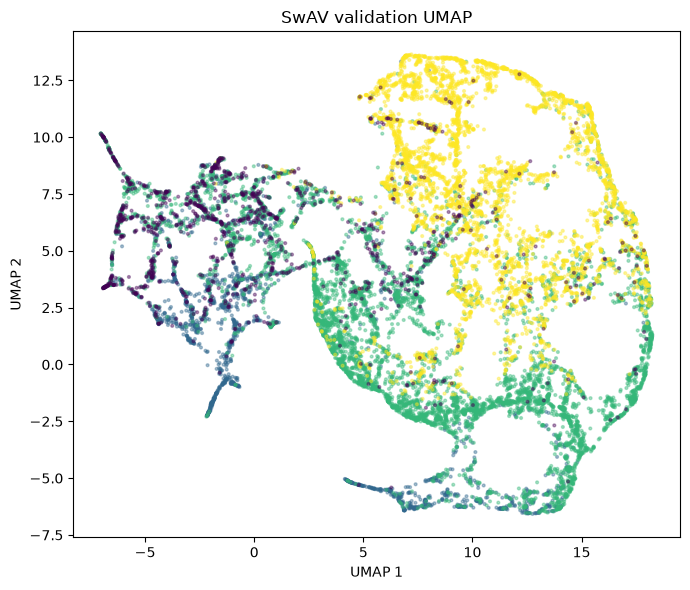

{'status': 'PASS', 'n_neighbors': 30, 'min_dist': 0.1, 'input_dimensions': 50}

In [5]:
umap_summary: dict[str, Any]

try:
    import umap

    reducer = umap.UMAP(
        n_neighbors=30,
        min_dist=0.1,
        n_components=2,
        metric="euclidean",
        random_state=42,
    )

    umap_coordinates = reducer.fit_transform(
        pca_result.coordinates
    )

    np.savez_compressed(
        ANALYSIS_ROOT
        / "embeddings"
        / "validation_umap_2d.npz",
        coordinates=umap_coordinates,
        crystal_ids=(
            validation_bundle.crystal_ids
        ),
        manifest_orders=(
            validation_bundle.manifest_orders
        ),
    )

    plt.figure(figsize=(7, 6))

    if locality_column is None:
        plt.scatter(
            umap_coordinates[:, 0],
            umap_coordinates[:, 1],
            s=4,
            alpha=0.35,
        )
    else:
        plt.scatter(
            umap_coordinates[:, 0],
            umap_coordinates[:, 1],
            c=locality_codes,
            s=4,
            alpha=0.4,
        )

    plt.xlabel("UMAP 1")
    plt.ylabel("UMAP 2")
    plt.title(
        f"{DISPLAY_NAME} validation UMAP"
    )

    save_current_figure(
        "validation_umap.png"
    )

    umap_summary = {
        "status": "PASS",
        "n_neighbors": 30,
        "min_dist": 0.1,
        "input_dimensions": 50,
    }

except Exception as error:
    umap_summary = {
        "status": "DEFERRED",
        "reason": repr(error),
    }

write_json(
    ANALYSIS_ROOT
    / "metadata"
    / "umap_summary.json",
    umap_summary,
)

umap_summary


## 5. Frozen validation clustering

K-means is evaluated across predeclared cluster counts and three random seeds.
Silhouette is calculated on one deterministic validation subset, while
stability is measured with pairwise adjusted Rand index.


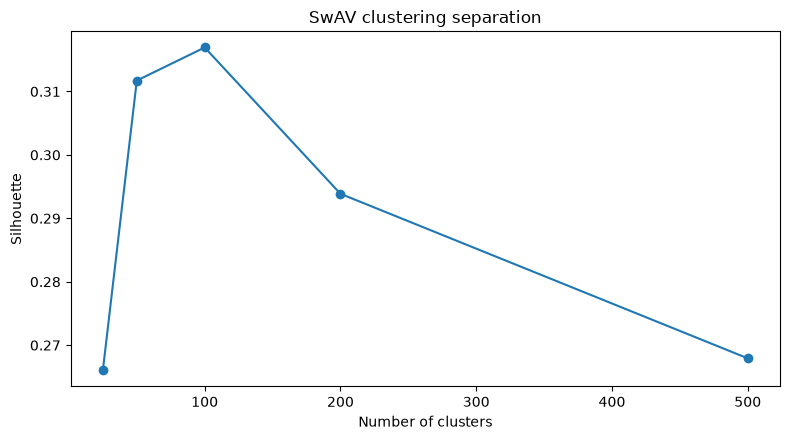

,number_of_clusters,seed,k,rows,dimensions,silhouette_sample_rows,silhouette,davies_bouldin,calinski_harabasz,inertia,inertia_per_row,iterations,occupied_clusters,minimum_cluster_size,maximum_cluster_size,minimum_cluster_fraction,maximum_cluster_fraction,normalised_cluster_entropy
0,25,42,25,14919,50,5000,0.266030,1.529461,1147.319012,3277.390381,0.219679,46,25,212,1861,0.014210,0.124740,0.964279
1,50,42,50,14919,50,5000,0.311717,1.175400,1126.541197,1981.248657,0.132800,30,50,100,729,0.006703,0.048864,0.971860
2,100,42,100,14919,50,5000,0.316936,1.026540,1111.335349,1108.274414,0.074286,46,100,51,416,0.003418,0.027884,0.972116
3,200,42,200,14919,50,5000,0.293868,1.059523,943.042675,679.027222,0.045514,60,200,21,258,0.001408,0.017293,0.972365
4,500,42,500,14919,50,5000,0.267924,1.045233,759.284216,342.291229,0.022943,24,500,1,136,0.000067,0.009116,0.972774


,number_of_clusters,k,seed_count,pair_count,mean_pairwise_ari,median_pairwise_ari,minimum_pairwise_ari,maximum_pairwise_ari,mean_pairwise_nmi,median_pairwise_nmi,minimum_pairwise_nmi,maximum_pairwise_nmi
0,25,25,3,3,0.549866,0.570931,0.501898,0.576767,0.796064,0.805427,0.772657,0.810109
1,50,50,3,3,0.646832,0.637591,0.613946,0.688960,0.846058,0.849990,0.830615,0.857571
2,100,100,3,3,0.658535,0.645222,0.634118,0.696264,0.880717,0.882191,0.877088,0.882872
3,200,200,3,3,0.627005,0.618025,0.600527,0.662463,0.867844,0.868154,0.858729,0.876650
4,500,500,3,3,0.621028,0.622968,0.594033,0.646081,0.889275,0.891088,0.883271,0.893467


,metadata,column,number_of_clusters,normalised_mutual_information
0,locality,locality,25,0.249058
1,locality,locality,50,0.236754
2,locality,locality,100,0.220988
3,locality,locality,200,0.205977
4,locality,locality,500,0.192320
5,sample,sample_id,25,0.269129
6,sample,sample_id,50,0.255471
7,sample,sample_id,100,0.238625
8,sample,sample_id,200,0.222444
9,sample,sample_id,500,0.208053


Median silhouette: 0.2938680648803711
Median stability ARI: 0.6229684686291584


In [6]:
K_VALUES = (25, 50, 100, 200, 500)
SEEDS = (42, 43, 44)

rng = np.random.default_rng(42)

silhouette_indices = np.sort(
    rng.choice(
        len(pca_result.coordinates),
        size=min(
            5000,
            len(pca_result.coordinates),
        ),
        replace=False,
    )
)

cluster_rows: list[dict[str, Any]] = []
stability_rows: list[dict[str, Any]] = []

primary_assignments: dict[int, np.ndarray] = {}

for number_of_clusters in K_VALUES:
    labels_by_seed = []

    for seed in SEEDS:
        labels, centroids, metrics = (
            evaluate_kmeans_run(
                pca_result.coordinates,
                number_of_clusters=(
                    number_of_clusters
                ),
                seed=seed,
                silhouette_indices=(
                    silhouette_indices
                ),
            )
        )

        labels_by_seed.append(labels)

        cluster_rows.append(
            {
                "number_of_clusters": (
                    number_of_clusters
                ),
                "seed": seed,
                **metrics,
            }
        )

        if seed == 42:
            primary_assignments[
                number_of_clusters
            ] = labels

            pd.DataFrame(
                {
                    "crystal_id": (
                        validation_bundle.crystal_ids
                    ),
                    "manifest_order": (
                        validation_bundle.manifest_orders
                    ),
                    "cluster": labels,
                }
            ).to_csv(
                ANALYSIS_ROOT
                / "clustering"
                / "assignments"
                / (
                    f"kmeans_k"
                    f"{number_of_clusters}_seed42.csv"
                ),
                index=False,
            )

    label_matrix = np.stack(
        labels_by_seed,
        axis=0,
    )

    pairwise_table, stability_summary = (
        pairwise_clustering_stability(
            label_matrix,
            seeds=SEEDS,
            number_of_clusters=(
                number_of_clusters
            ),
        )
    )

    pairwise_table.to_csv(
        ANALYSIS_ROOT
        / "clustering"
        / (
            f"kmeans_k"
            f"{number_of_clusters}_stability.csv"
        ),
        index=False,
    )

    stability_rows.append(
        {
            "number_of_clusters": (
                number_of_clusters
            ),
            **stability_summary,
        }
    )

cluster_table = pd.DataFrame(
    cluster_rows
)

stability_table = pd.DataFrame(
    stability_rows
)

cluster_table.to_csv(
    ANALYSIS_ROOT
    / "tables"
    / "clustering_runs.csv",
    index=False,
)

stability_table.to_csv(
    ANALYSIS_ROOT
    / "tables"
    / "clustering_stability.csv",
    index=False,
)

primary_cluster_table = (
    cluster_table.loc[
        cluster_table["seed"] == 42
    ]
    .sort_values("number_of_clusters")
    .reset_index(drop=True)
)

median_silhouette = float(
    primary_cluster_table[
        "silhouette"
    ].median()
)

ari_columns = [
    column
    for column in stability_table.columns
    if "ari" in column.lower()
    and "median" in column.lower()
]

if not ari_columns:
    raise RuntimeError(
        "Could not identify median stability ARI."
    )

median_stability_ari = float(
    stability_table[
        ari_columns[0]
    ].median()
)

metadata_associations = []

for metadata_name, metadata_column in (
    ("locality", locality_column),
    (
        "sample",
        resolve_column(
            validation_manifest,
            (
                "sample_id",
                "sample",
                "sample_name",
                "specimen_id",
            ),
        ),
    ),
    (
        "source_image",
        resolve_column(
            validation_manifest,
            (
                "source_image",
                "source_image_id",
                "source_scan",
                "parent_image",
                "image_source",
            ),
        ),
    ),
):
    if metadata_column is None:
        continue

    values = validation_manifest[
        metadata_column
    ].astype(str).to_numpy()

    for number_of_clusters, labels in (
        primary_assignments.items()
    ):
        metadata_associations.append(
            {
                "metadata": metadata_name,
                "column": metadata_column,
                "number_of_clusters": (
                    number_of_clusters
                ),
                "normalised_mutual_information": float(
                    normalized_mutual_info_score(
                        values,
                        labels,
                    )
                ),
            }
        )

association_table = pd.DataFrame(
    metadata_associations
)

association_table.to_csv(
    ANALYSIS_ROOT
    / "tables"
    / "cluster_metadata_associations.csv",
    index=False,
)

plt.figure(figsize=(8, 4.5))

plt.plot(
    primary_cluster_table[
        "number_of_clusters"
    ],
    primary_cluster_table["silhouette"],
    marker="o",
)

plt.xlabel("Number of clusters")
plt.ylabel("Silhouette")
plt.title(
    f"{DISPLAY_NAME} clustering separation"
)

save_current_figure(
    "clustering_silhouette.png"
)

display(primary_cluster_table)
display(stability_table)
display(association_table.head(20))

print(
    "Median silhouette:",
    median_silhouette,
)

print(
    "Median stability ARI:",
    median_stability_ari,
)


## 6. Exact cosine retrieval and confounding diagnostics

Retrieval is calculated in the original 512-dimensional backbone space.
Cross-sample retrieval excludes crystals from the same physical sample.
No image pixels are opened during automated notebook execution.


In [7]:
cosine_features = prepare_cosine_features(
    validation_bundle.features
)

raw_neighbour_indices, raw_similarities = (
    exact_cosine_neighbours(
        cosine_features,
        neighbour_count=20,
        chunk_size=256,
    )
)

sample_column = resolve_column(
    validation_manifest,
    (
        "sample_id",
        "sample",
        "sample_name",
        "specimen_id",
    ),
)

source_image_column = resolve_column(
    validation_manifest,
    (
        "source_image",
        "source_image_id",
        "source_scan",
        "parent_image",
        "image_source",
    ),
)

retrieval_metrics: dict[str, Any] = {
    "test_split_accessed": False,
    "image_pixels_accessed": False,
}

if locality_column is not None:
    locality_labels = (
        validation_manifest[
            locality_column
        ]
        .astype(str)
        .to_numpy()
    )

    for k in (5, 10, 20):
        retrieval_metrics[
            f"same_locality_precision_at_{k}"
        ] = categorical_precision_at_k(
            raw_neighbour_indices,
            locality_labels,
            k=k,
        )
else:
    locality_labels = None

if sample_column is not None:
    sample_labels = (
        validation_manifest[
            sample_column
        ]
        .astype(str)
        .to_numpy()
    )

    retrieval_metrics[
        "same_sample_precision_at_10"
    ] = categorical_precision_at_k(
        raw_neighbour_indices,
        sample_labels,
        k=10,
    )

    sample_codes = pd.factorize(
        sample_labels,
        sort=True,
    )[0].astype(np.int64)

    (
        cross_sample_indices,
        cross_sample_similarities,
    ) = exact_cosine_neighbours(
        cosine_features,
        neighbour_count=10,
        exclusion_codes=sample_codes,
        chunk_size=256,
    )

    if locality_labels is not None:
        fct_mask = (
            np.char.upper(
                locality_labels.astype(str)
            )
            == "FCT"
        )

        retrieval_metrics[
            "automatic_fct_cross_sample_p10_raw"
        ] = categorical_precision_at_k(
            cross_sample_indices,
            locality_labels,
            k=10,
            query_mask=fct_mask,
        )
else:
    cross_sample_indices = None
    cross_sample_similarities = None

if source_image_column is not None:
    source_labels = (
        validation_manifest[
            source_image_column
        ]
        .astype(str)
        .to_numpy()
    )

    source_enrichment = (
        categorical_enrichment_at_k(
            raw_neighbour_indices,
            source_labels,
            k=10,
        )
    )

    retrieval_metrics[
        "source_image_enrichment_at10_raw"
    ] = source_enrichment["enrichment"]

    retrieval_metrics[
        "source_image_enrichment_details"
    ] = source_enrichment

np.savez_compressed(
    ANALYSIS_ROOT
    / "retrieval"
    / "validation_cosine_neighbours.npz",
    indices=raw_neighbour_indices,
    similarities=raw_similarities,
)

if cross_sample_indices is not None:
    np.savez_compressed(
        ANALYSIS_ROOT
        / "retrieval"
        / (
            "validation_cross_sample_"
            "cosine_neighbours.npz"
        ),
        indices=cross_sample_indices,
        similarities=(
            cross_sample_similarities
        ),
    )

write_json(
    ANALYSIS_ROOT
    / "retrieval"
    / "retrieval_metrics.json",
    retrieval_metrics,
)

query_rows = np.linspace(
    0,
    len(validation_manifest) - 1,
    num=20,
    dtype=int,
)

neighbour_rows = []

for query_index in query_rows:
    for rank, neighbour_index in enumerate(
        raw_neighbour_indices[
            query_index,
            :10,
        ],
        start=1,
    ):
        neighbour_rows.append(
            {
                "query_crystal_id": (
                    validation_bundle.crystal_ids[
                        query_index
                    ]
                ),
                "neighbour_rank": rank,
                "neighbour_crystal_id": (
                    validation_bundle.crystal_ids[
                        neighbour_index
                    ]
                ),
                "cosine_similarity": float(
                    raw_similarities[
                        query_index,
                        rank - 1,
                    ]
                ),
            }
        )

pd.DataFrame(
    neighbour_rows
).to_csv(
    ANALYSIS_ROOT
    / "retrieval"
    / "deterministic_query_neighbours.csv",
    index=False,
)

display(
    pd.DataFrame(
        [retrieval_metrics]
    )
)


,test_split_accessed,image_pixels_accessed,same_locality_precision_at_5,same_locality_precision_at_10,same_locality_precision_at_20,same_sample_precision_at_10,automatic_fct_cross_sample_p10_raw
0,False,False,0.738642,0.73153,0.723554,0.716556,0.236171


## 7. Train-to-validation locality probe

A balanced multinomial logistic-regression probe is fitted on frozen training
embeddings and evaluated on frozen validation embeddings. This measures
locality-associated information, which may reflect geological signal,
acquisition effects or both.


In [8]:
locality_probe_summary: dict[str, Any]

train_locality_column = resolve_column(
    train_manifest,
    (
        "locality",
        "volcano",
        "site",
    ),
)

if (
    train_locality_column is None
    or locality_column is None
):
    locality_probe_summary = {
        "status": "DEFERRED",
        "reason": (
            "Locality column was not available "
            "in both manifests."
        ),
    }

    locality_macro_f1 = None

else:
    locality_probe = fit_locality_probe(
        train_bundle.features,
        train_manifest[
            train_locality_column
        ].astype(str).to_numpy(),
        validation_bundle.features,
        validation_manifest[
            locality_column
        ].astype(str).to_numpy(),
        regularisation_c=1.0,
        class_weight="balanced",
        maximum_iterations=500,
        tolerance=1e-5,
        seed=42,
    )

    locality_probe_summary = {
        "status": "PASS",
        **locality_probe.summary,
    }

    locality_macro_f1 = float(
        locality_probe.summary[
            "metrics"
        ]["locality_macro_f1"]
    )

    locality_probe.per_class_metrics.to_csv(
        ANALYSIS_ROOT
        / "probes"
        / "locality_per_class_metrics.csv",
        index=False,
    )

    locality_probe.confusion_matrix.to_csv(
        ANALYSIS_ROOT
        / "probes"
        / "locality_confusion_matrix.csv",
    )

    locality_probe.predictions.to_csv(
        ANALYSIS_ROOT
        / "probes"
        / "locality_validation_predictions.csv",
        index=False,
    )

write_json(
    ANALYSIS_ROOT
    / "probes"
    / "locality_probe_summary.json",
    locality_probe_summary,
)

display(
    pd.DataFrame(
        [
            locality_probe_summary.get(
                "metrics",
                locality_probe_summary,
            )
        ]
    )
)


/home/ars223/MSc-GEMS/IRP26/plagnetplus-dev/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,locality_macro_f1,balanced_accuracy,accuracy,validation_log_loss,prediction_outside_validation_class_rate,training_majority_class,training_majority_baseline_accuracy,training_majority_baseline_macro_f1
0,0.426771,0.50799,0.437362,2.500361,0.167773,Methana,0.473959,0.160778


## 8. SwAV prototype diagnostics

The 500 learned 128-dimensional prototypes are checked for unit norm,
finite values, redundancy and representational rank.


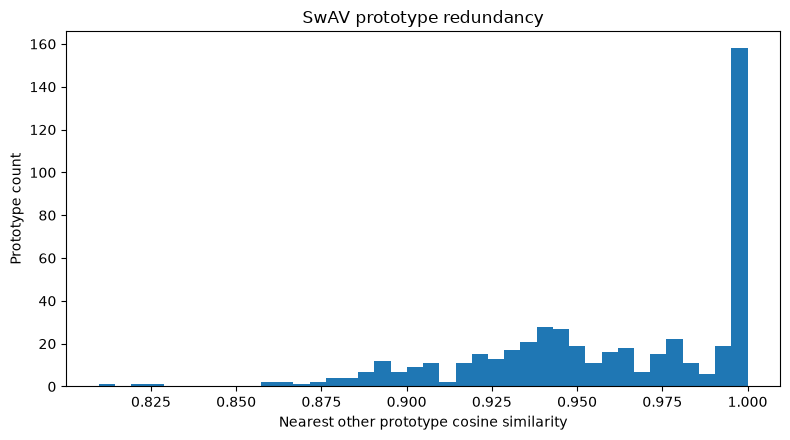

,shape,norm_minimum,norm_mean,norm_maximum,mean_nearest_prototype_similarity,maximum_nearest_prototype_similarity,prototype_effective_rank,prototype_participation_ratio
0,"[500, 128]",1.0,1.0,1.0,0.959354,1.0,74.811833,0.584467


In [9]:
with np.load(
    RUN_ROOT
    / "embeddings"
    / "prototype_weights.npz",
    allow_pickle=False,
) as prototype_archive:
    prototype_weights = (
        prototype_archive["weights"]
        .astype(np.float32)
    )

    prototype_indices = (
        prototype_archive[
            "prototype_indices"
        ]
    )

assert prototype_weights.shape == (
    500,
    128,
)

assert np.isfinite(
    prototype_weights
).all()

prototype_norms = np.linalg.norm(
    prototype_weights,
    axis=1,
)

normalised_prototypes = (
    prototype_weights
    / prototype_norms[:, None]
)

prototype_similarity = (
    normalised_prototypes
    @ normalised_prototypes.T
)

np.fill_diagonal(
    prototype_similarity,
    -np.inf,
)

nearest_prototype_similarity = (
    prototype_similarity.max(axis=1)
)

prototype_effective_rank, (
    prototype_participation_ratio
) = entropy_effective_rank(
    prototype_weights
)

prototype_summary = {
    "shape": list(
        prototype_weights.shape
    ),
    "norm_minimum": float(
        prototype_norms.min()
    ),
    "norm_mean": float(
        prototype_norms.mean()
    ),
    "norm_maximum": float(
        prototype_norms.max()
    ),
    "mean_nearest_prototype_similarity": float(
        nearest_prototype_similarity.mean()
    ),
    "maximum_nearest_prototype_similarity": float(
        nearest_prototype_similarity.max()
    ),
    "prototype_effective_rank": float(
        prototype_effective_rank
    ),
    "prototype_participation_ratio": float(
        prototype_participation_ratio
    ),
}

write_json(
    ANALYSIS_ROOT
    / "metadata"
    / "swav_prototype_summary.json",
    prototype_summary,
)

pd.DataFrame(
    {
        "prototype_index": (
            prototype_indices
        ),
        "norm": prototype_norms,
        "nearest_other_similarity": (
            nearest_prototype_similarity
        ),
    }
).to_csv(
    ANALYSIS_ROOT
    / "tables"
    / "prototype_diagnostics.csv",
    index=False,
)

plt.figure(figsize=(8, 4.5))

plt.hist(
    nearest_prototype_similarity,
    bins=40,
)

plt.xlabel(
    "Nearest other prototype cosine similarity"
)
plt.ylabel("Prototype count")
plt.title("SwAV prototype redundancy")

save_current_figure(
    "prototype_nearest_similarity.png"
)

display(
    pd.DataFrame(
        [prototype_summary]
    )
)


## 9. Frozen result summary

The common comparison metrics are exported in the same schema used by the
existing model analyses. Expert texture retrieval remains unmeasured rather
than being inferred from automatic locality diagnostics.


In [10]:
def find_numeric(
    value: Any,
    key_tokens: tuple[str, ...],
) -> float | None:
    if isinstance(value, dict):
        for key, item in value.items():
            lowered = str(key).lower()

            if all(
                token in lowered
                for token in key_tokens
            ):
                if isinstance(
                    item,
                    (int, float),
                ):
                    return float(item)

        for item in value.values():
            found = find_numeric(
                item,
                key_tokens,
            )

            if found is not None:
                return found

    if isinstance(value, list):
        for item in value:
            found = find_numeric(
                item,
                key_tokens,
            )

            if found is not None:
                return found

    return None

gpu_hours = find_numeric(
    run_summary,
    ("gpu", "hours"),
)

if gpu_hours is None:
    gpu_hours = {
        "simsiam": 5.802153604833357,
        "swav": 5.8432944832321825,
    }[METHOD]

comparison_metrics = {
    "median_silhouette_across_k": (
        median_silhouette
    ),
    "median_stability_ari_across_k": (
        median_stability_ari
    ),
    "automatic_fct_cross_sample_p10_raw": (
        retrieval_metrics.get(
            "automatic_fct_cross_sample_p10_raw"
        )
    ),
    "expert_cross_sample_texture_p10": None,
    "locality_macro_f1": locality_macro_f1,
    "source_image_enrichment_at10_raw": (
        retrieval_metrics.get(
            "source_image_enrichment_at10_raw"
        )
    ),
    "validation_effective_rank": float(
        effective_rank
    ),
    "gpu_hours": float(gpu_hours),
}

analysis_summary = {
    "schema_version": (
        "plagnetplus_ssl_analysis_v1"
    ),
    "model_id": RUN_NAME,
    "method": METHOD,
    "display_name": DISPLAY_NAME,
    "backbone": "resnet18",
    "status": "PASS",
    "benchmark": {
        "benchmark_id": (
            contract["benchmark_id"]
        ),
        "development_split": "validation",
        "test_split_accessed": False,
        "train_rows": int(
            train_bundle.features.shape[0]
        ),
        "validation_rows": int(
            validation_bundle.features.shape[0]
        ),
    },
    "embedding": {
        "dimension": 512,
        "train_shape": list(
            train_bundle.features.shape
        ),
        "validation_shape": list(
            validation_bundle.features.shape
        ),
        "finite": True,
    },
    "training": {
        "epochs": 100,
        "amp_disabled_for_recovery": True,
        "final_train": (
            history_train.iloc[-1].to_dict()
        ),
        "final_validation": (
            history_validation.iloc[-1].to_dict()
        ),
    },
    "comparison_metrics": comparison_metrics,
    "interpretation": {
        "clusters_are_diagnostics": True,
        "expert_texture_metric_pending": True,
        "test_split_reserved": True,
    },
}

write_json(
    ANALYSIS_ROOT
    / "analysis_summary.json",
    analysis_summary,
)

summary_row = {
    "model_id": RUN_NAME,
    "method": METHOD,
    "backbone": "resnet18",
    "status": "PASS",
    **comparison_metrics,
    "test_split_accessed": 0,
}

pd.DataFrame(
    [summary_row]
).to_csv(
    ANALYSIS_ROOT
    / "tables"
    / f"{METHOD}_summary.csv",
    index=False,
)

pd.DataFrame(
    [summary_row]
).to_csv(
    ANALYSIS_ROOT
    / "tables"
    / "registry_candidate.csv",
    index=False,
)

display(
    pd.DataFrame(
        [summary_row]
    )
)

print()
print(
    f"{DISPLAY_NAME} ANALYSIS: PASS"
)
print(
    "Test split accessed: False"
)
print(
    f"Analysis summary: "
    f"{ANALYSIS_ROOT / 'analysis_summary.json'}"
)


,model_id,method,backbone,status,median_silhouette_across_k,median_stability_ari_across_k,automatic_fct_cross_sample_p10_raw,expert_cross_sample_texture_p10,locality_macro_f1,source_image_enrichment_at10_raw,validation_effective_rank,gpu_hours,test_split_accessed
0,swav_resnet18_pooled_broad_natural_seed42_full...,swav,resnet18,PASS,0.293868,0.622968,0.236171,None,0.426771,None,48.747709,5.843294,0



SwAV ANALYSIS: PASS
Test split accessed: False
Analysis summary: /home/ars223/MSc-GEMS/IRP26/runs/analysis/swav/swav_resnet18_pooled_broad_natural_seed42_full_3447013_v1/analysis_summary.json
